# N2: Assistente de Leitura de Editais de Leilão com LLM

**Disciplina:** Inteligência Artificial, FCI, Universidade Presbiteriana Mackenzie

**Integrantes**
- Luiz Eduardo Bacha dos Santos (RA 10425296), 10425296@mackenzista.com.br
- Guilherme Haddad Borro (RA 10427699), 10427699@mackenzista.com.br

**Conteúdo:** execução comentada da fase de desenvolvimento (N2): prompt e esquema de saída, chamada ao LLM,
linha de base sem IA, avaliação (completude, fidelidade, concordância e legibilidade) e exemplo de dossiê.
O processamento pesado fica nos scripts de `src/`; este notebook explica cada etapa e mostra os resultados.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-11-17 | Luiz Eduardo Bacha dos Santos | criação do notebook da N2 (pipeline + resultados) |

In [1]:
# Configuração: os módulos do projeto ficam em ../src
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import assistente_edital as A   # pipeline LLM
import baseline_regras as B     # linha de base sem IA
RES = RAIZ / "resultados"
print("Modelo padrão:", A.MODELO, "| endpoint:", A.BASE_URL)

Modelo padrão: gemini-flash-lite-latest | endpoint: https://generativelanguage.googleapis.com/v1beta/openai


## 1. Prompt do sistema e esquema de saída

O modelo recebe um papel (consultor para leigos), regras anti-alucinação (usar só o texto, `null` quando não houver
informação, **evidência literal** para cada campo) e um esquema JSON fixo. Temperatura 0.

In [2]:
print(A.PROMPT_SISTEMA)

Você é um consultor que explica editais de leilão de imóveis para pessoas LEIGAS, sem formação jurídica. Você recebe o texto de um edital e a identificação de UM lote.

REGRAS OBRIGATÓRIAS
1. Use SOMENTE informações que estão no texto do edital. Não use conhecimento externo para inventar valores, datas, dívidas ou ônus.
2. Se uma informação não aparece no edital, use null (ou lista vazia) e diga "não informado no edital".
3. Para cada campo factual, preencha "evidencia" com um trecho LITERAL e curto (até 200 caracteres), copiado exatamente do edital, que comprova a resposta. Se não houver trecho, use null.
4. Valores em reais devem ser números (ex.: 250000.0), sem "R$".
5. O edital pode trazer vários lotes: responda apenas sobre o lote indicado. Regras gerais (pagamento, comissão, débitos) que valem para todos os lotes também se aplicam a ele.
6. Explicações em português simples: frases curtas, sem juridiquês. Se precisar usar um termo técnico, explique o que ele significa.
7. Isto NÃO

## 2. Amostra usada

Um lote por edital (vários lotes compartilham o mesmo PDF), estratificado por tipo de leilão, semente 42.

In [3]:
lotes = A.carregar_lotes()
amostra = pd.read_csv(RES / "amostra.csv", dtype=str)
print(len(lotes), "lotes no dataset |", lotes.edital_url.nunique(), "editais distintos |", len(amostra), "na amostra")
amostra.tipo_leilao.value_counts()

87 lotes no dataset | 66 editais distintos | 30 na amostra


tipo_leilao
Extrajudicial    20
Judicial         10
Name: count, dtype: int64

## 3. Execução do assistente

A execução completa é feita por linha de comando (exige a chave da API em `LLM_API_KEY`):

```bash
python src/assistente_edital.py --amostra 30
```

Abaixo, o log de cada chamada (tempo, tokens, validade do JSON).

In [4]:
log = pd.read_csv(RES / "execucao_llm.csv", dtype={"lote_id": str})
log.tail(10)

,lote_id,leilao_id,chars_edital,segundos,tokens_entrada,tokens_saida,modelo,json_valido,erro
21,fc888045,edaba27c4,6734.0,4.0,3128.0,1275.0,gemini-flash-lite-latest,True,NaN
22,084e22e5,ea983b2a5,8170.0,3.7,3355.0,1197.0,gemini-flash-lite-latest,True,NaN
23,bd2419a4,e72a2594e,8401.0,4.7,3420.0,1439.0,gemini-flash-lite-latest,True,NaN
24,07bba0ba,eef1b4f4e,12694.0,3.9,4775.0,1180.0,gemini-flash-lite-latest,True,NaN
25,19d3d285,eeb0ce9da,8173.0,3.9,3348.0,1068.0,gemini-flash-lite-latest,True,NaN
26,32afeb99,eb200cbdb,8459.0,4.9,3466.0,1460.0,gemini-flash-lite-latest,True,NaN
27,6b62aa4b,e5a93165c,7104.0,4.0,3094.0,1338.0,gemini-flash-lite-latest,True,NaN
28,2e3a60a0,eb80931b5,11223.0,3.6,4269.0,1044.0,gemini-flash-lite-latest,True,NaN
29,9ae0c42a,e020db171,8353.0,3.6,3460.0,1131.0,gemini-flash-lite-latest,True,NaN
30,f0c8a438,e2a047575,7503.0,3.1,3165.0,880.0,gemini-flash-lite-latest,True,NaN


## 4. Linha de base sem IA (regras / regex)

In [5]:
base = pd.read_csv(RES / "baseline_regras.csv", dtype={"lote_id": str})
base.head()

,lote_id,leilao_id,tipo_leilao,ocupacao,avaliacao,lance_minimo_1,comissao_pct,debitos_arrematante,onus,n_onus,parcelamento,glossario
0,90e32ce1,e11ee84f4,Extrajudicial,Não informado,1250000.0,NaN,5.0,False,Penhora,1,True,arrematante;penhora;IPTU;condomínio;dívida ati...
1,9969b4e9,efa290ca1,Extrajudicial,Não informado,300000.0,NaN,5.0,False,Penhora,1,True,arrematante;penhora;IPTU;condomínio;dívida ati...
2,128409,eeae166a1,Extrajudicial,Não informado,NaN,NaN,5.0,True,Hipoteca;Penhora;Alienação fiduciária,3,False,alienação fiduciária;arrematante;hipoteca;penh...
3,01cff60d,e5288b628,Extrajudicial,Não informado,310000.0,NaN,5.0,True,Alienação fiduciária,1,True,alienação fiduciária;arrematante;IPTU;condomín...
4,128817,e1c46eb84,Extrajudicial,Desocupado,NaN,NaN,5.0,True,NaN,0,False,arrematante;condomínio;comissão do leiloeiro;m...


## 5. Avaliação

Gerada por `python src/avaliar.py`. Métricas sem anotação manual:
- **Completude**: campos preenchidos (LLM x regras)
- **Fidelidade**: evidências literais e valores em R$ que existem no edital; termos do glossário presentes no texto
- **Concordância**: tipo de leilão x regra da N1; avaliação x valor do site; comissão e ocupação x regras
- **Legibilidade**: Índice de Flesch adaptado ao português (Martins et al., 1996)

In [6]:
met = json.loads((RES / "metricas.json").read_text(encoding="utf-8"))
print(json.dumps({k: met[k] for k in ["modelo", "lotes_processados", "json_valido_pct", "tempo_medio_s",
                                      "tokens_entrada_medio", "tokens_saida_medio"]}, ensure_ascii=False, indent=1))
pd.DataFrame(met["completude"]).T.rename(columns={"llm": "LLM (%)", "regras": "Regras (%)"})

{
 "modelo": "gemini-flash-lite-latest",
 "lotes_processados": 29,
 "json_valido_pct": 96.6,
 "tempo_medio_s": 4.9,
 "tokens_entrada_medio": 5500,
 "tokens_saida_medio": 1238
}


,LLM (%),Regras (%)
Tipo de leilão,100.0,100.0
Ocupação,32.1,3.6
Avaliação (R$),71.4,64.3
Lance mínimo (R$),100.0,0.0
Comissão (%),100.0,100.0


In [7]:
print(json.dumps(met["fidelidade"], ensure_ascii=False, indent=1))
print(json.dumps(met["concordancia"], ensure_ascii=False, indent=1))
print("Flesch (mediana):", met["legibilidade_flesch"])
print("Risco:", met["risco"])

{
 "evidencias_citadas": 221,
 "evidencias_encontradas_pct": 99.1,
 "evidencias_por_campo_pct": {
  "comissao": 100.0,
  "divida": 97.9,
  "ocupacao": 100.0,
  "onus": 97.3,
  "pagamento": 100.0,
  "tipo_leilao": 100.0,
  "valores": 100.0
 },
 "valores_rs_citados": 98,
 "valores_rs_encontrados_pct": 71.4,
 "glossario_termos": 58,
 "glossario_no_texto_pct": 98.3
}
{
 "tipo_llm_x_regra_n1": {
  "n": 28,
  "pct": 64.3
 },
 "avaliacao_llm_x_site_1pct": {
  "n": 0,
  "pct": null
 },
 "avaliacao_regras_x_site_1pct": {
  "n": 0,
  "pct": null
 },
 "comissao_llm_x_regras": {
  "n": 28,
  "pct": 100.0
 },
 "ocupacao_llm_x_regras": {
  "n": 1,
  "pct": 100.0
 },
 "ocupacao_llm_x_site": {
  "n": 0,
  "pct": null
 }
}
Flesch (mediana): {'edital_mediana': 40.7, 'gerado_mediana': 51.349999999999994}
Risco: {'Alto': 20, 'Médio': 8}


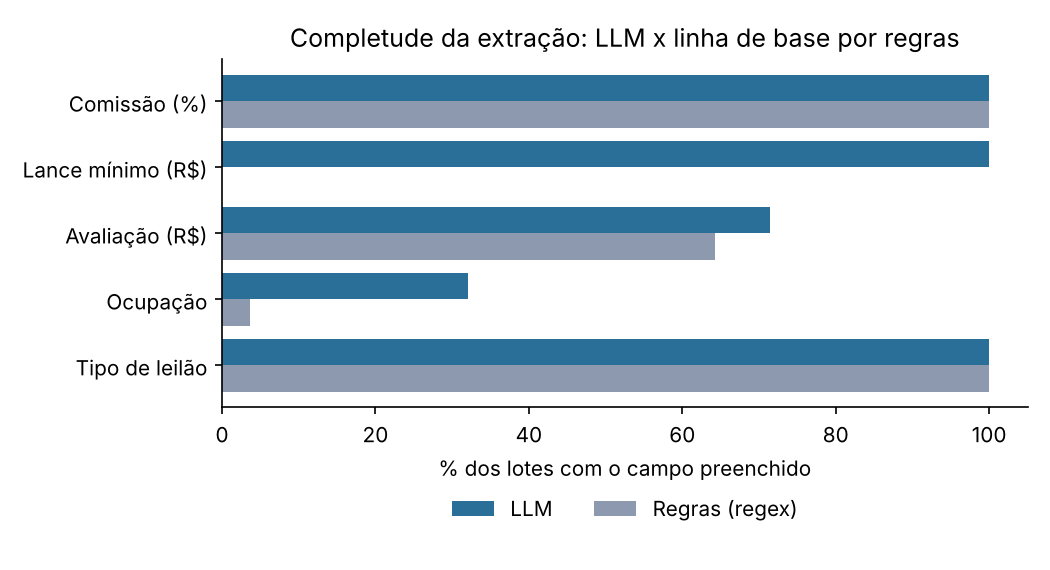

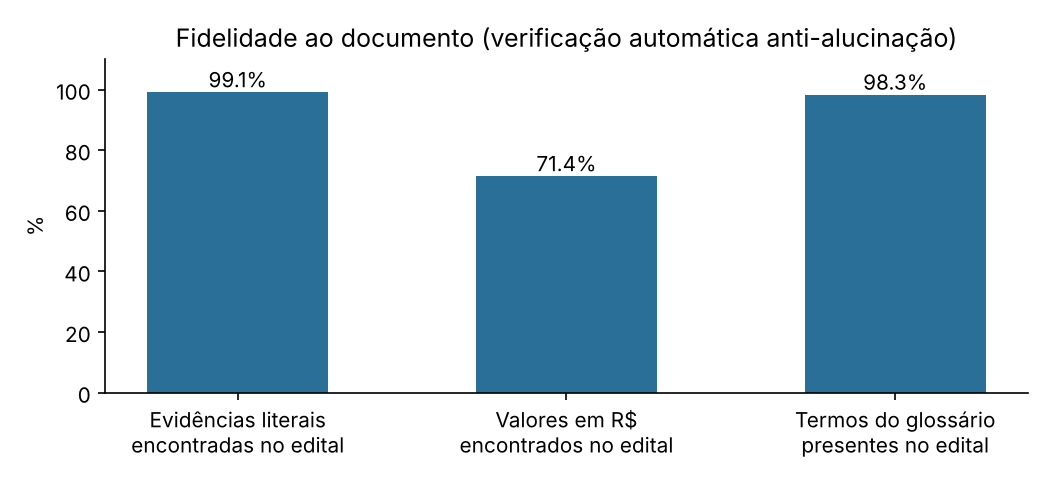

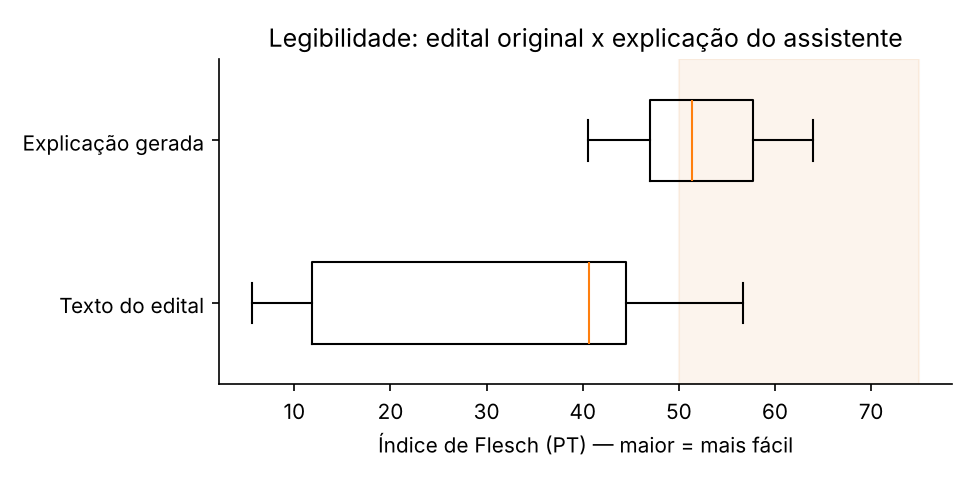

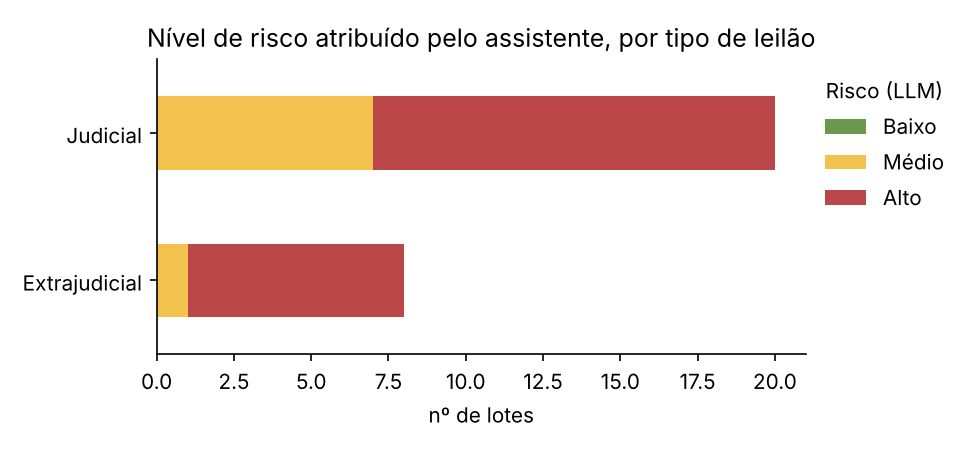

In [8]:
for f in ["08_completude_llm_x_regras.png", "09_fidelidade.png", "10_legibilidade.png", "11_risco_por_tipo.png"]:
    display(Image(filename=str(RAIZ / "figuras" / f)))

### 5.1 Evidências e valores que não foram encontrados no texto (análise de erros)

In [9]:
ev = pd.read_csv(RES / "fidelidade_evidencias.csv", dtype={"lote_id": str})
ev[~ev.encontrada.astype(bool)].head(15)

,lote_id,campo,encontrada,evidencia
7,90e32ce1,onus,False,Penhora no rosto dos autos sobre eventuais cré...
75,128548,divida,False,O COMPRADOR é responsável... por despesas de c...


In [10]:
vr = pd.read_csv(RES / "fidelidade_valores.csv", dtype={"lote_id": str})
vr[~vr.encontrado.astype(bool)].head(15)

,lote_id,campo,valor,encontrado
2,90e32ce1,lance_minimo_2,1125000.00,False
5,9969b4e9,lance_minimo_2,180000.00,False
11,252d6593,lance_minimo_2,1579140.21,False
18,3da5e19d,lance_minimo_2,1086000.00,False
21,3cbc5db9,lance_minimo_2,886498.75,False
22,3cbc5db9,divida,93072.77,False
31,716074bd,lance_minimo_2,256500.00,False
36,00a0cb1f,lance_minimo_2,201500.00,False
37,00a0cb1f,divida,29167.47,False
38,00a0cb1f,divida,521181.30,False


## 6. Exemplo de dossiê gerado para um lote

In [11]:
tab = pd.read_csv(RES / "tabela_lotes_llm.csv", dtype={"lote_id": str})
exemplo = tab[tab.json_valido.astype(bool)].sort_values("llm_n_dividas", ascending=False).iloc[0].lote_id
display(Markdown((RES / "dossies" / f"{exemplo}.md").read_text(encoding="utf-8")))

# Dossiê do lote 128548 — Garagem Santo Amaro (219.0 m²)

> Ferramenta de apoio à leitura. **Não é aconselhamento jurídico.**

**Resumo:** Este leilão refere-se a um apartamento de 219 m² com 4 vagas de garagem em Santo Amaro, São Paulo. O imóvel está ocupado e é vendido no estado em que se encontra. O primeiro leilão exige lance mínimo de cerca de 2,44 milhões de reais, e o segundo de 1,30 milhão. O pagamento deve ser feito à vista em até 24 horas, somado à comissão de 5% do leiloeiro. O comprador assume os riscos e custos com a desocupação, transferência, impostos e eventuais débitos pendentes.

- **Tipo de leilão:** Extrajudicial — O leilão é realizado com base na Lei nº 9.514/97, que trata da alienação fiduciária de imóveis.
- **Ocupação:** Ocupado — O imóvel encontra-se ocupado, ficando a desocupação por conta do arrematante.
- **Avaliação:** não informado | **1º lance mínimo:** R$ 2.442.530,79 | **2º lance mínimo:** R$ 1.302.575,55
- **Comissão do leiloeiro:** 5.0%
- **Dívidas por conta do comprador (soma):** não informado
- **Nível de risco:** Alto

## Dívidas e encargos

- IPTU: não informado — responsável: Arrematante. O arrematante é responsável pelos impostos e taxas que incidam sobre o imóvel a partir da arrematação, bem como pelo rateio do IPTU do exercício vigente.
- Condomínio: não informado — responsável: Arrematante. O adquirente assume as despesas de condomínio a partir da arrematação.
- Outros: não informado — responsável: Arrematante. Débitos de água e energia anteriores ou posteriores à arrematação ficam a cargo do comprador.

## Ônus (restrições no imóvel)

- **Alienação fiduciária**: O imóvel foi dado em garantia de financiamento, tendo sua propriedade consolidada em nome do credor fiduciário.

## Pagamento

Pagamento à vista do valor total da arrematação e da comissão do leiloeiro no prazo de até 24 horas após a comunicação.

## Por que esse risco?

- Imóvel ocupado, exigindo ação de desocupação por conta do comprador.
- Responsabilidade do arrematante por eventuais débitos de água, energia e taxas.
- O vendedor não responde pela evicção de direito em caso de anulação da aquisição.

## Glossário

- **Alienação fiduciária**: Garantia em que o devedor entrega a propriedade do imóvel ao credor até pagar toda a dívida.
- **Ad corpus**: Venda do imóvel pelo todo, sem garantia de medidas exatas da área.

**Recomendação:** Consulte um advogado especialista imobiliário antes de dar lances, pois o imóvel está ocupado e há diversas despesas e responsabilidades transferidas ao comprador.


## 7. Demonstração interativa

`pip install streamlit` e `streamlit run app.py`: envie o PDF de um edital e veja o dossiê na tela.